# Turtle Breakout 03 — intraday windows and volatility-engine sizing

Pre-registration: `discussions/Turtle_Breakout/005_claude_tb03_preregistration.md`. Code: `turtle_breakout.py` (h4 periods, engine sizing), `turtle_intraday.py`.

Nine strategies on BTC/ETH/SOL/XRP perpetuals (long only, 2% HWM risk, fees + slippage + funding):

| timeframe | entry / trailing stop / ATR |
|---|---|
| `daily` | 20-day high / 10-day low / 20 days (TB 01) |
| `h4_candles` | 20 × 4h bars (80 h) / 10 bars (40 h) / 20 bars |
| `last_4h` | high of the last 4 hours / low of the last 2 hours / 4 hours (1h bars) |

× sizing `atr` (original), `engine` (engine sets the size), `engine_stop` (engine sets size and fixed stop). Engine unit $U=c\,\sigma_{\text{engine}}P$, with $c$ a causal median of ATR/$(\sigma P)$.

Per strategy: G1 random entries, G2 vs TB 02 benchmarks (Bonferroni over 9). Contrasts C1–C8 (Bonferroni over 8).

Environment: `TB01_DATA_DIR`, `TB03_SYNTHETIC=1`, `TB03_NULL_SCALE` (e.g. 0.1 for a quick look; the decision uses 1).

In [1]:
import os, sys, json, time, subprocess, tempfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_benchmarks as bm, turtle_intraday as ti, vwap_drift as vd

SYNTHETIC = os.getenv('TB03_SYNTHETIC', '0') == '1'
SCALE = float(os.getenv('TB03_NULL_SCALE', '1'))
ASSETS = list(tb.ASSETS); CP = ti.CParams()
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb03-')) / '03'; CP = ti.CParams(n_boot=300); SCALE = min(SCALE, 0.05)
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '03'
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
    DATA = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
for t in ('test_turtle_breakout.py', 'test_turtle_benchmarks.py', 'test_turtle_intraday.py'):
    chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', t], cwd=str(ROOT), env=env, capture_output=True, text=True)
    print(t, chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0, t
FITS = vd.load_engine(ROOT / 'notebooks' / 'Volatility_Dynamics' / '18' / '18_manifest.json')
print(json.dumps(ti.registration(CP), indent=1, default=str)[:3000])

test_turtle_breakout.py OK
test_turtle_benchmarks.py OK
test_turtle_intraday.py OK
{
 "n_strategies": 9,
 "n_contrasts": 8,
 "alpha": 0.05,
 "block_days": 21,
 "n_boot": 2000,
 "seed": 20261026,
 "bench_lev_cap": 1.0,
 "status": "PREREGISTERED_TB005",
 "version": "TB03-0.1.0",
 "timeframes": {
  "daily": {
   "period": "day"
  },
  "h4_candles": {
   "period": "h4"
  },
  "last_4h": {
   "period": "hour",
   "entry_n": 4,
   "exit_n": 2,
   "atr_n": 4
  }
 },
 "sizings": [
  "atr",
  "engine",
  "engine_stop"
 ],
 "n_null": {
  "daily": 1000,
  "h4_candles": 400,
  "last_4h": 200
 },
 "contrasts": [
  {
   "id": "C1",
   "a": "daily|engine",
   "b": "daily|atr"
  },
  {
   "id": "C2",
   "a": "h4_candles|engine",
   "b": "h4_candles|atr"
  },
  {
   "id": "C3",
   "a": "last_4h|engine",
   "b": "last_4h|atr"
  },
  {
   "id": "C4",
   "a": "daily|engine_stop",
   "b": "daily|atr"
  },
  {
   "id": "C5",
   "a": "h4_candles|engine_stop",
   "b": "h4_candles|atr"
  },
  {
   "id": "C6",


## 1. Data

In [2]:
T0 = time.time(); B5, FUND = {}, {}
for k, a in enumerate(ASSETS):
    if SYNTHETIC:
        b = tb.synthetic_5m(2200, seed=40 + k, trend=0.01, start='2019-11-01'); f = tb.synthetic_funding(b, 0.0001)
    else:
        b = tb.bars_5m(pd.read_parquet(DATA / f'{a}USDT_um_1m.parquet', columns=['open_time', 'open', 'high', 'low', 'close']))
        f = tb.funding_events(pd.read_parquet(DATA / 'basis' / 'funding' / f'{a}USDT_funding.parquet'))
    B5[a], FUND[a] = b, f; print(a, len(b), f'{time.time() - T0:.0f}s')
END = min(b.index[-1] for b in B5.values())
print('window', tb.COMMON_START.date(), '->', END)

BTC 716544 1s
ETH 716544 2s
SOL 641004 3s
XRP 713564 4s
window 2020-10-15 -> 2026-10-24 00:00:00+00:00


## 2. Nine strategies: simulation, random-entry nulls, benchmark tests

In [3]:
RES, ROWS, BTEST, NULLS = {}, [], [], []
for tf in ti.TIMEFRAMES:
    p0 = ti.strategy_params(tf, 'engine')
    t1 = time.time(); DATA_TF = {a: tb.prepare_asset(a, B5[a], FUND[a], p0, engine=FITS) for a in ASSETS}
    Cp, Fp = bm.daily_panel(DATA_TF, tb.COMMON_START, END)
    print(f'{tf}: prepared in {time.time() - t1:.0f}s')
    for sz in ti.SIZINGS:
        name = f'{tf}|{sz}'; p = ti.strategy_params(tf, sz); t1 = time.time()
        E, T, ST = tb.simulate(DATA_TF, p, start=tb.COMMON_START, end=END)
        n_null = max(20, int(round(ti.N_NULL[tf] * SCALE)))
        NULL = tb.random_portfolios(DATA_TF, p, ST['p_entry'], tb.COMMON_START, END, n=n_null, seed=p.seed + 2)
        row, tests = ti.evaluate_strategy(name, E, T, ST, NULL, Cp, Fp, p.fee + p.slip, CP)
        RES[name] = (E, T, ST); ROWS.append(row); NULLS.append(NULL.assign(strategy=name))
        BTEST += [{'strategy': name, 'benchmark': k, **v} for k, v in tests.items()]
        print(f"  {name:24s} cagr {row['cagr']:7.3f} sharpe {row['sharpe']:5.2f} maxdd {row['max_dd']:6.3f} trades {row['trades']:5d} "
              f"lev {row['mean_leverage']:4.2f} null share {row['null_share_cagr_ge_real']:.4f} -> {row['verdict']}  ({time.time() - t1:.0f}s)")
S = pd.DataFrame(ROWS).set_index('strategy')
display(S[['cagr', 'sharpe', 'max_dd', 'trades', 'win_rate', 'profit_factor', 'avg_hold_days', 'mean_leverage', 'leverage_capped_entries',
           'engine_used', 'engine_fallback', 'fees', 'funding', 'null_cagr_median', 'null_share_cagr_ge_real', 'G1',
           'B1_diff', 'B1_lo', 'B2_lo', 'B3_lo', 'G2', 'verdict']].round(3))

daily: prepared in 4s
  daily|atr                cagr   0.745 sharpe  1.57 maxdd -0.361 trades   180 lev 0.41 null share 0.0000 -> BEATS_LUCK_ONLY  (59s)
  daily|engine             cagr   0.415 sharpe  1.42 maxdd -0.324 trades   180 lev 0.28 null share 0.0550 -> NO_EDGE  (60s)
  daily|engine_stop        cagr   0.427 sharpe  1.45 maxdd -0.321 trades   175 lev 0.28 null share 0.0270 -> NO_EDGE  (60s)
h4_candles: prepared in 3s
  h4_candles|atr           cagr   1.552 sharpe  1.27 maxdd -0.764 trades  1190 lev 1.09 null share 0.0000 -> BEATS_LUCK_ONLY  (131s)
  h4_candles|engine        cagr   1.050 sharpe  1.15 maxdd -0.643 trades  1190 lev 0.86 null share 0.0000 -> BEATS_LUCK_ONLY  (133s)
  h4_candles|engine_stop   cagr   1.114 sharpe  1.18 maxdd -0.705 trades  1155 lev 0.88 null share 0.0000 -> BEATS_LUCK_ONLY  (132s)
last_4h: prepared in 4s
  last_4h|atr              cagr  -0.996 sharpe  0.33 maxdd -1.000 trades 20577 lev 3.80 null share 0.5050 -> NO_EDGE  (329s)
  last_4h|engine       

,cagr,sharpe,max_dd,trades,win_rate,profit_factor,avg_hold_days,mean_leverage,leverage_capped_entries,engine_used,engine_fallback,fees,funding,null_cagr_median,null_share_cagr_ge_real,G1,B1_diff,B1_lo,B2_lo,B3_lo,G2,verdict
strategy,,,,,,,,,,,,,,,,,,,,,,
daily|atr,0.745,1.566,-0.361,180,0.406,2.419,17.582,0.412,0,0,0,67361.987,287767.825,0.239,0.000,PASS,0.503,-0.316,-0.309,-0.449,FAIL,BEATS_LUCK_ONLY
daily|engine,0.415,1.425,-0.324,180,0.406,2.511,17.582,0.281,0,180,0,16019.862,84384.474,0.210,0.055,FAIL,0.346,-0.539,-0.516,-0.701,FAIL,NO_EDGE
daily|engine_stop,0.427,1.452,-0.321,175,0.417,2.610,18.578,0.285,0,175,0,15959.029,86895.613,0.195,0.027,FAIL,0.374,-0.483,-0.473,-0.640,FAIL,NO_EDGE
h4_candles|atr,1.552,1.267,-0.764,1190,0.339,1.221,2.576,1.090,22,0,0,9420793.157,3471915.321,0.382,0.000,PASS,0.267,-0.631,-0.629,-0.869,FAIL,BEATS_LUCK_ONLY
h4_candles|engine,1.050,1.149,-0.643,1190,0.339,1.303,2.576,0.859,3,1190,0,1810641.626,754274.114,0.278,0.000,PASS,0.135,-0.793,-0.785,-1.057,FAIL,BEATS_LUCK_ONLY
h4_candles|engine_stop,1.114,1.183,-0.705,1155,0.349,1.339,2.748,0.881,4,1155,0,1948330.793,849076.148,0.323,0.000,PASS,0.171,-0.754,-0.737,-1.047,FAIL,BEATS_LUCK_ONLY
last_4h|atr,-0.996,0.330,-1.000,20577,0.299,0.994,0.159,3.799,17121,0,0,2847550.000,313761.206,-0.996,0.505,FAIL,-0.671,-1.750,-1.754,-1.937,FAIL,NO_EDGE
last_4h|engine,-0.996,0.421,-1.000,20577,0.299,0.990,0.159,3.895,17885,20567,10,1550288.449,222796.096,-0.996,0.530,FAIL,-0.580,-1.608,-1.625,-1.743,FAIL,NO_EDGE
last_4h|engine_stop,-0.996,0.419,-1.000,20559,0.299,0.990,0.159,3.901,17869,20549,10,1545982.722,222525.069,-0.996,0.570,FAIL,-0.581,-1.610,-1.618,-1.759,FAIL,NO_EDGE


## 3. Contrasts (Bonferroni over 8)

In [4]:
EQ = {k: v[0] for k, v in RES.items()}
CT = ti.contrasts(EQ, CP)
display(CT.round(3))

,contrast,a,b,sharpe_a,sharpe_b,diff,lo,hi,ci_level,days,result
0,C1,daily|engine,daily|atr,1.425,1.566,-0.141,-0.431,0.166,0.994,2200,NO_DIFFERENCE
1,C2,h4_candles|engine,h4_candles|atr,1.149,1.268,-0.118,-0.296,0.030,0.994,2200,NO_DIFFERENCE
2,C3,last_4h|engine,last_4h|atr,0.421,0.330,0.091,-0.111,0.326,0.994,2200,NO_DIFFERENCE
3,C4,daily|engine_stop,daily|atr,1.453,1.566,-0.113,-0.430,0.260,0.994,2200,NO_DIFFERENCE
4,C5,h4_candles|engine_stop,h4_candles|atr,1.183,1.268,-0.084,-0.319,0.131,0.994,2200,NO_DIFFERENCE
5,C6,last_4h|engine_stop,last_4h|atr,0.419,0.330,0.090,-0.128,0.363,0.994,2200,NO_DIFFERENCE
6,C7,h4_candles|atr,daily|atr,1.268,1.566,-0.299,-1.151,0.588,0.994,2200,NO_DIFFERENCE
7,C8,last_4h|atr,daily|atr,0.330,1.566,-1.237,-2.404,-0.021,0.994,2200,B_BETTER


## 4. Reported: per-asset P&L, years, benchmark detail

In [5]:
per_asset = pd.concat({k: v[1].groupby('asset').agg(trades=('pnl', 'size'), pnl=('pnl', 'sum'), fees=('fees', 'sum'),
                        funding=('funding', 'sum'), ret_notional_sum=('ret_notional', 'sum')) for k, v in RES.items()}, names=['strategy'])
display(per_asset.round(2))
YR = pd.DataFrame({k: tb.yearly(v[0]) for k, v in RES.items()})
display((100 * YR).round(1))
BT = pd.DataFrame(BTEST); display(BT.round(3))

trades          pnl        fees     funding  ret_notional_sum
strategy               asset                                                               
daily|atr              BTC        49    464580.00    23180.57    84891.90              1.75
                       ETH        44    401413.77    16857.32    74179.03              2.87
                       SOL        46    578861.87    13956.87    57829.50              8.46
                       XRP        41   1318313.51    13367.22    70867.40              5.93
daily|engine           BTC        49    158804.85     5825.02    28673.49              1.75
                       ETH        44    170611.53     4149.60    24289.15              2.87
                       SOL        46    140147.27     3293.74    15280.56              8.46
                       XRP        41    238240.36     2751.50    16141.29              5.93
daily|engine_stop      BTC        49    156990.41     5918.40    29117.41              1.71
                       ETH        43    155894.88     4201.44    24712.44              2.84
                       SOL        43    192768.31     3071.53    16211.12              9.06
                       XRP        40    245146.07     2767.66    16854.65              5.80
h4_candles|atr         BTC       302  -1508025.57  3461349.37  1062511.97              1.31
                       ETH       307  11511174.12  2130956.19   922909.04              1.17
                       SOL       308  -3292301.56  2015283.67   616576.59              2.19
                       XRP       273  21451967.29  1813203.92   869917.73              4.77
h4_candles|engine      BTC       302    345988.44   654221.43   225841.49              1.31
                       ETH       307   1950610.15   434502.56   212611.79              1.17
                       SOL       308   -207255.15   365935.70   112253.13              2.19
                       XRP       273   5352671.00   355981.94   203567.71              4.77
h4_candles|engine_stop BTC       292   1215444.31   688907.84   259504.25              1.50
                       ETH       302   1962099.14   480730.25   237536.32              1.38
                       SOL       293     52577.61   387094.98   124641.03              3.02
                       XRP       268   5755112.90   391597.73   227394.55              4.71
last_4h|atr            BTC      5191  -1065830.87   937306.42    75550.15             -4.67
                       ETH      5150    -17431.53   767562.65    87574.26             -2.80
                       SOL      5078   1375421.75   489397.06    60037.80              0.38
                       XRP      5158   -392159.35   653283.87    90598.99             -3.90
last_4h|engine         BTC      5191   -690585.57   516766.41    53385.48             -4.67
                       ETH      5150    -47602.10   419029.11    63783.89             -2.80
                       SOL      5078    886861.02   269418.43    41039.68              0.38
                       XRP      5158   -248673.34   345074.51    64587.05             -3.90
last_4h|engine_stop    BTC      5182   -689014.66   515422.32    53319.02             -4.58
                       ETH      5145    -47441.01   417944.00    63718.06             -2.72
                       SOL      5076    884207.61   268624.26    40985.63              0.30
                       XRP      5156   -247751.95   343992.14    64502.36             -3.92

,daily|atr,daily|engine,daily|engine_stop,h4_candles|atr,h4_candles|engine,h4_candles|engine_stop,last_4h|atr,last_4h|engine,last_4h|engine_stop
2020,59.4,37.6,37.4,210.3,162.4,168.7,95.7,92.9,92.9
2021,123.6,63.4,63.8,144.9,82.2,99.3,-88.8,-99.4,-99.5
2022,-20.4,-17.1,-16.5,-40.7,-53.0,-60.1,-100.0,-100.0,-100.0
2023,213.9,88.6,87.1,664.8,392.5,495.2,-99.7,-94.6,-93.8
2024,107.4,58.5,61.7,234.1,160.0,143.5,134.8,134.8,134.8
2025,17.5,25.9,30.7,69.4,53.1,54.0,-74.2,-74.2,-79.7
2026,32.0,15.2,14.5,44.8,71.1,90.2,65.1,65.1,110.1


,strategy,benchmark,sharpe_a,sharpe_b,diff,lo,hi,ci_level,days
0,daily|atr,B1,1.567,1.064,0.503,-0.316,1.383,0.994,2199
1,daily|atr,B2,1.567,0.936,0.630,-0.309,1.508,0.994,2199
2,daily|atr,B3,1.567,1.213,0.354,-0.449,1.244,0.994,2199
3,daily|engine,B1,1.425,1.079,0.346,-0.539,1.251,0.994,2199
4,daily|engine,B2,1.425,0.936,0.490,-0.516,1.402,0.994,2199
5,daily|engine,B3,1.425,1.233,0.193,-0.701,1.129,0.994,2199
6,daily|engine_stop,B1,1.453,1.079,0.374,-0.483,1.298,0.994,2199
7,daily|engine_stop,B2,1.453,0.936,0.517,-0.473,1.417,0.994,2199
8,daily|engine_stop,B3,1.453,1.232,0.221,-0.640,1.123,0.994,2199
9,h4_candles|atr,B1,1.268,1.001,0.267,-0.631,1.115,0.994,2199


## 5. Figures

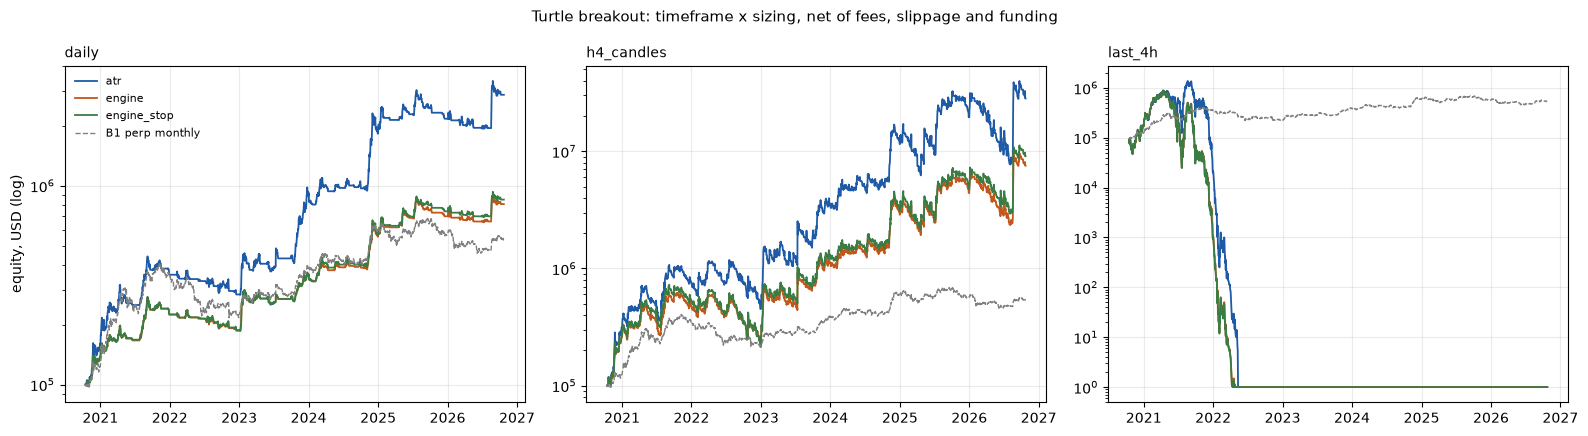

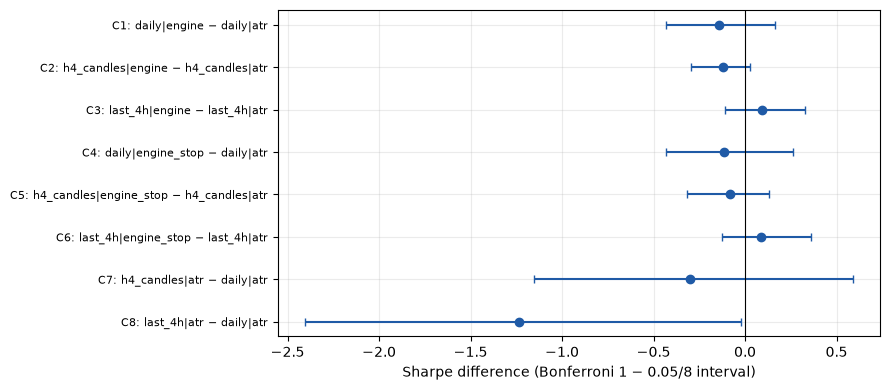

In [6]:
Cd, Fd = bm.daily_panel({a: tb.prepare_asset(a, B5[a], FUND[a], tb.Params()) for a in ASSETS}, tb.COMMON_START, END)
B1 = bm.constant_mix(Cd, Fd, min(S.loc['daily|atr', 'mean_leverage'], 1.0), 'M', True, tb.Params().fee + tb.Params().slip)
cols = {'atr': '#1f5aa6', 'engine': '#c2571a', 'engine_stop': '#3a7d44'}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=False)
for ax, tf in zip(axes, ti.TIMEFRAMES):
    for sz, c in cols.items():
        e = tb.daily(RES[f'{tf}|{sz}'][0]); ax.plot(e.index, e.clip(lower=1), color=c, lw=1.3, label=sz)
    b1 = tb.daily(B1); ax.plot(b1.index, b1, color='0.5', lw=1, ls='--', label='B1 perp monthly')
    ax.set_yscale('log'); ax.set_title(tf, loc='left', fontsize=10); ax.grid(alpha=0.25)
axes[0].set_ylabel('equity, USD (log)'); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('Turtle breakout: timeframe x sizing, net of fees, slippage and funding', fontsize=11)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(CT))
ax.errorbar(CT['diff'], y, xerr=[CT['diff'] - CT.lo, CT.hi - CT['diff']], fmt='o', color='#1f5aa6', capsize=3)
ax.axvline(0, color='k', lw=0.8); ax.set_yticks(y); ax.set_yticklabels([f"{r.contrast}: {r.a} − {r.b}" for r in CT.itertuples()], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel('Sharpe difference (Bonferroni 1 − 0.05/8 interval)'); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 6. Exports

In [7]:
S.to_csv(OUT / '03_strategies.csv', float_format='%.6g'); CT.to_csv(OUT / '03_contrasts.csv', index=False, float_format='%.6g')
BT.to_csv(OUT / '03_benchmark_tests.csv', index=False, float_format='%.6g'); YR.to_csv(OUT / '03_yearly.csv', float_format='%.6g')
per_asset.to_csv(OUT / '03_per_asset.csv', float_format='%.6g')
pd.DataFrame({k: tb.daily(v[0]) for k, v in RES.items()} | {'B1_perp_monthly': tb.daily(B1)}).to_csv(OUT / '03_equity_daily.csv', float_format='%.2f')
pd.concat([v[1].assign(strategy=k) for k, v in RES.items()], ignore_index=True).to_csv(OUT / '03_trades.csv.gz', index=False, float_format='%.6g')
pd.concat(NULLS, ignore_index=True).to_csv(OUT / '03_null_runs.csv.gz', index=False, float_format='%.5g')
(OUT / '03_decision.json').write_text(json.dumps({'strategies': S[['cagr', 'sharpe', 'max_dd', 'G1', 'G2', 'verdict']].to_dict('index'),
    'contrasts': CT[['contrast', 'a', 'b', 'diff', 'lo', 'hi', 'result']].to_dict('records'),
    'null_scale': SCALE, 'registration': ti.registration(CP)}, indent=1, default=float))
(OUT / '03_manifest.json').write_text(json.dumps({'module': 'Turtle_Breakout_03', 'version': ti.VERSION, 'synthetic': SYNTHETIC,
    'null_scale': SCALE, 'window': [str(tb.COMMON_START), str(END)], 'runtime_s': round(time.time() - T0, 1)}, indent=1))
print(sorted(p.name for p in OUT.iterdir()))

['03_benchmark_tests.csv', '03_contrasts.csv', '03_decision.json', '03_equity_daily.csv', '03_manifest.json', '03_null_runs.csv.gz', '03_per_asset.csv', '03_strategies.csv', '03_trades.csv.gz', '03_yearly.csv']
